# NHANES Audiogram Completion — Full Analysis Pipeline
**Run cells in order. Each cell saves its outputs so later cells can reload them.**

| Cell | Content | Runtime |
|------|---------|--------|
| 1 | Data download — all 4 NHANES cycles | ~5 min |
| 2 | EDA — Figures 1 & 2 | ~30 sec |
| 3 | Modeling (Ridge/RF/XGBoost), 5-fold CV — Figures 3 & 4 | ~12 min |
| 4 | SHAP importance + Bootstrap CIs — Figures 5 & 6 | ~10 min |
| 5 | Temporal validation + Calibration — Figure 7 | ~5 min |

In [1]:
# ============================================================
# CELL 1 — NHANES Data Download  (run once per session)
# Downloads all 4 audiometry cycles, cleans, saves CSV.
# Runtime: ~4-6 min (download-bound)
# ============================================================

import pandas as pd
import numpy as np
import requests
from io import BytesIO
import warnings
warnings.filterwarnings("ignore")

SAVE_PATH = "/content/nhanes_all_cycles.csv"

# ── Explicit URLs per cycle (2013-2014 uses older CDC path) ──
CYCLE_URLS = {
    "2011-2012": {
        "audio": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/AUX_G.XPT",
        "demo":  "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/DEMO_G.XPT",
    },
    "2013-2014": {
        # This cycle lives at the older CDC URL — do NOT change
        "audio": "https://wwwn.cdc.gov/Nchs/Nhanes/2013-2014/AUX_H.XPT",
        "demo":  "https://wwwn.cdc.gov/Nchs/Nhanes/2013-2014/DEMO_H.XPT",
    },
    "2015-2016": {
        "audio": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/AUX_I.XPT",
        "demo":  "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/DEMO_I.XPT",
    },
    "2017-2018": {
        "audio": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/AUX_J.XPT",
        "demo":  "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.XPT",
    },
}

DEMO_VARS = ["SEQN","RIDAGEYR","RIAGENDR","RIDRETH3",
             "DMDEDUC2","INDFMPIR","WTINT2YR"]

FREQ_MAP = {"500":"500Hz","1K":"1000Hz","2K":"2000Hz",
            "3K":"3000Hz","4K":"4000Hz","6K":"6000Hz","8K":"8000Hz"}

FREQ_COLS = ["R_500Hz","R_1000Hz","R_2000Hz","R_3000Hz","R_4000Hz","R_6000Hz","R_8000Hz",
             "L_500Hz","L_1000Hz","L_2000Hz","L_3000Hz","L_4000Hz","L_6000Hz","L_8000Hz"]

def load_xpt(url):
    print(f"    GET {url}")
    r = requests.get(url, timeout=120)
    if r.status_code != 200:
        raise Exception(f"HTTP {r.status_code}")
    if b"<html" in r.content[:500].lower():
        raise Exception("Got HTML page instead of XPT binary")
    return pd.read_sas(BytesIO(r.content), format="xport", encoding="utf-8")

def build_rename(columns):
    rmap, used = {}, set()
    for col in columns:
        if col.startswith("AUXU") and col.endswith(("R","L")):
            ear = col[-1]
            for key, label in FREQ_MAP.items():
                if key in col:
                    t = f"{ear}_{label}"
                    if t not in used:
                        rmap[col] = t
                        used.add(t)
                    break
    return rmap

# ── Download & process each cycle ────────────────────────────
all_frames = []

for cycle, urls in CYCLE_URLS.items():
    print(f"\n=== {cycle} ===")
    try:
        aud = load_xpt(urls["audio"])
        dem = load_xpt(urls["demo"])
        dem = dem[[c for c in DEMO_VARS if c in dem.columns]]
        merged = aud.merge(dem, on="SEQN", how="inner")
        merged["cycle"] = cycle
        all_frames.append(merged)
        print(f"  Merged rows: {len(merged)}")
    except Exception as e:
        print(f"  FAILED: {e}")

df = pd.concat(all_frames, ignore_index=True)
df = df.loc[:, ~df.columns.duplicated()]

# ── Rename columns ────────────────────────────────────────────
df.rename(columns={
    **build_rename(df.columns),
    "RIDAGEYR":"age","RIAGENDR":"gender","RIDRETH3":"race_eth",
    "DMDEDUC2":"education","INDFMPIR":"poverty_ratio","WTINT2YR":"survey_weight",
}, inplace=True)

# ── Age filter ────────────────────────────────────────────────
df = df[(df["age"] >= 20) & (df["age"] <= 69)].copy()

# ── Clean thresholds ──────────────────────────────────────────
fc = [c for c in FREQ_COLS if c in df.columns]
for col in fc:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col] == 666, col] = np.nan
    df.loc[df[col] > 110,  col] = np.nan
    df.loc[df[col] < -10,  col] = np.nan

df = df.dropna(subset=fc).copy()

# ── Harmonise noise exposure (2011-2016: AUQ020A-E, 2017-2018: AUQ550A-E) ──
old_n = [c for c in ["AUQ020A","AUQ020B","AUQ020C","AUQ020D","AUQ020E"] if c in df.columns]
new_n = [c for c in ["AUQ550A","AUQ550B","AUQ550C","AUQ550D","AUQ550E"] if c in df.columns]
old_any = (df[old_n].apply(pd.to_numeric, errors="coerce") == 1).any(axis=1) if old_n else pd.Series(False, index=df.index)
new_any = (df[new_n].apply(pd.to_numeric, errors="coerce") == 1).any(axis=1) if new_n else pd.Series(False, index=df.index)
df["any_noise_exposure"] = old_any.astype(float)
df.loc[df["any_noise_exposure"].isna(), "any_noise_exposure"] = new_any

# ── Labels ────────────────────────────────────────────────────
race_map = {1.0:"Mexican American",2.0:"Other Hispanic",3.0:"Non-Hispanic White",
            4.0:"Non-Hispanic Black",6.0:"Non-Hispanic Asian",7.0:"Other/Multiracial"}
df["race_eth_label"] = df["race_eth"].map(race_map)
df["gender_label"]   = df["gender"].map({1.0:"Male",2.0:"Female"})

# ── PTA + HL severity (ASCII labels — consistent throughout) ──
df["PTA_better"] = df[["R_500Hz","R_1000Hz","R_2000Hz","R_4000Hz",
                        "L_500Hz","L_1000Hz","L_2000Hz","L_4000Hz"]].mean(axis=1)

def hl_cat(p):
    if p < 25:  return "Normal (<25 dB)"
    elif p < 40: return "Mild (25-40 dB)"
    else:        return "Mod+ (>=40 dB)"

df["HL_severity"] = df["PTA_better"].apply(hl_cat)

# ── Summary ──────────────────────────────────────────────────
print(f"\n{'='*45}")
print(f"FINAL DATASET")
print(f"{'='*45}")
print(f"Total complete audiograms: {len(df)}")
print(f"\nBy cycle:")
print(df["cycle"].value_counts())
print(f"\nBy race/ethnicity:")
print(df["race_eth_label"].value_counts())
print(f"\nHL severity:")
print(df["HL_severity"].value_counts())
print(f"\nAge: {df['age'].mean():.1f} +/- {df['age'].std():.1f}")
print(f"Female: {(df['gender']==2.0).mean()*100:.1f}%")
print(f"\nNoise exposure by cycle:")
print(df.groupby("cycle")["any_noise_exposure"].agg(["count","mean"]).round(3))

df.to_csv(SAVE_PATH, index=False)
print(f"\nSaved -> {SAVE_PATH}")



=== 2011-2012 ===
    GET https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/AUX_G.XPT
    GET https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/DEMO_G.XPT
  Merged rows: 4500

=== 2013-2014 ===
    GET https://wwwn.cdc.gov/Nchs/Nhanes/2013-2014/AUX_H.XPT
  FAILED: Got HTML page instead of XPT binary

=== 2015-2016 ===
    GET https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/AUX_I.XPT
    GET https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/DEMO_I.XPT
  Merged rows: 4582

=== 2017-2018 ===
    GET https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/AUX_J.XPT
    GET https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.XPT
  Merged rows: 3131

FINAL DATASET
Total complete audiograms: 8069

By cycle:
cycle
2015-2016    4256
2011-2012    3813
Name: count, dtype: int64

By race/ethnicity:
race_eth_label
Non-Hispanic White    2595
Non-Hispanic Black    1999
Mexican American      1169
Non-Hispanic Asian    1069
Other Hispanic   

Loaded 8069 rows


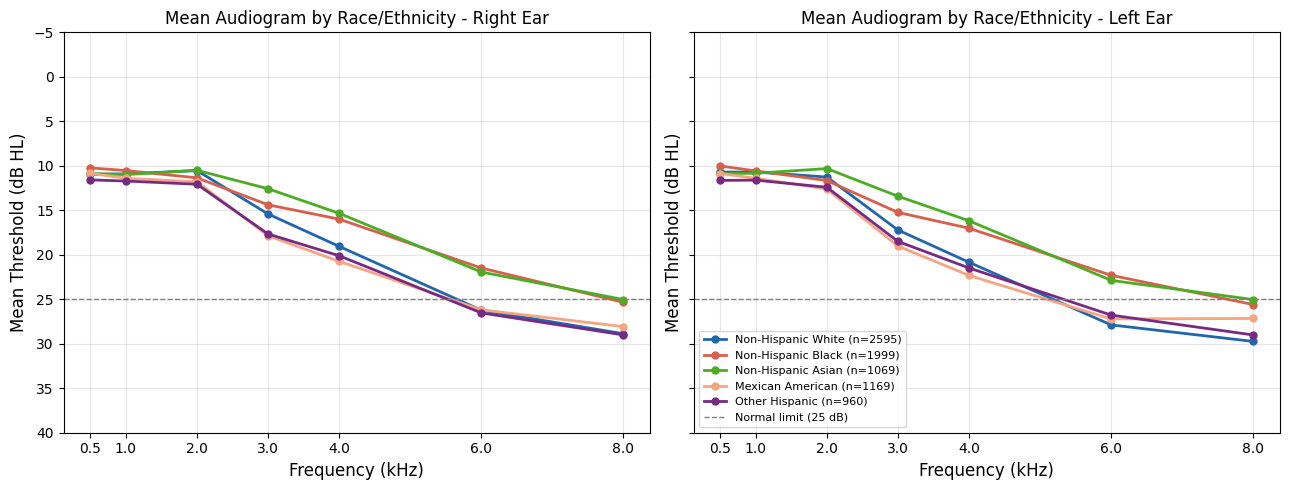

Saved: fig1_audiogram_by_race.png


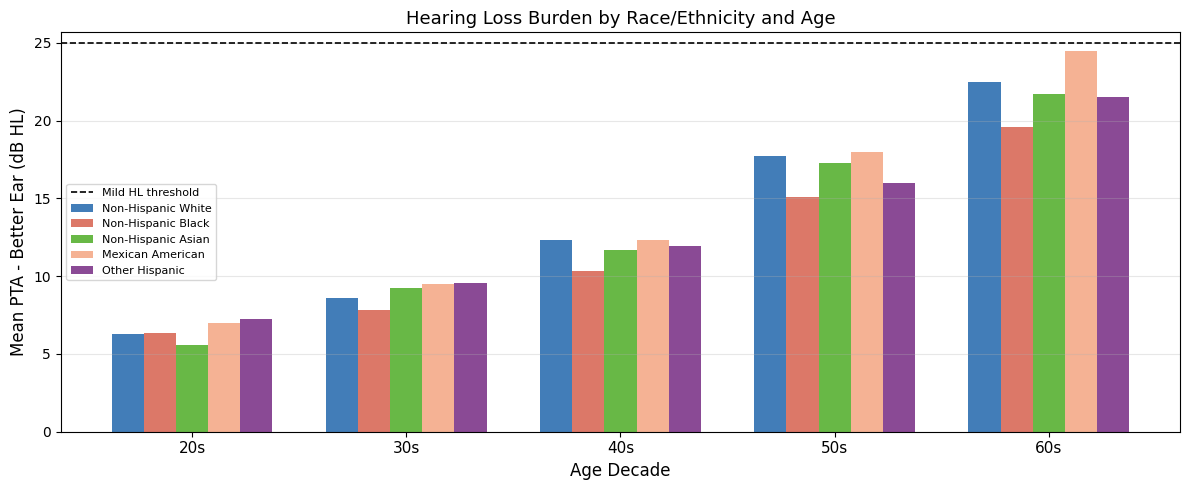

Saved: fig2_pta_race_age.png

--- Hearing Loss Distribution ---
HL_severity
Normal (<25 dB)    7091
Mild (25-40 dB)     768
Mod+ (>=40 dB)      210
Name: count, dtype: int64

Mean PTA better ear: 12.9 +/- 10.3 dB


In [6]:
# ============================================================
# CELL 2 — Exploratory Data Analysis (Figures 1 & 2)
# Runtime: ~30 sec
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("/content/nhanes_all_cycles.csv")
print(f"Loaded {len(df)} rows")

RACE_ORDER  = ["Non-Hispanic White","Non-Hispanic Black","Non-Hispanic Asian",
               "Mexican American","Other Hispanic"]
RACE_COLORS = ["#2166ac","#d6604d","#4dac26","#f4a582","#762a83"]
FREQS       = [0.5,1.0,2.0,3.0,4.0,6.0,8.0]
R_COLS = ["R_500Hz","R_1000Hz","R_2000Hz","R_3000Hz","R_4000Hz","R_6000Hz","R_8000Hz"]
L_COLS = ["L_500Hz","L_1000Hz","L_2000Hz","L_3000Hz","L_4000Hz","L_6000Hz","L_8000Hz"]

# ── Figure 1: Mean audiogram by race/ethnicity ────────────────
fig, axes = plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,(cols,label) in zip(axes,[(R_COLS,"Right Ear"),(L_COLS,"Left Ear")]):
    for race,color in zip(RACE_ORDER,RACE_COLORS):
        sub  = df[df["race_eth_label"]==race]
        vals = sub[cols].mean().values
        ax.plot(FREQS, vals, marker="o", label=f"{race} (n={len(sub)})",
                color=color, linewidth=2, markersize=5)
    ax.set_xlabel("Frequency (kHz)",fontsize=12)
    ax.set_ylabel("Mean Threshold (dB HL)",fontsize=12)
    ax.set_title(f"Mean Audiogram by Race/Ethnicity - {label}",fontsize=12)
    ax.invert_yaxis(); ax.set_ylim(40,-5)
    ax.set_xticks(FREQS); ax.set_xticklabels([str(f) for f in FREQS])
    ax.axhline(25,color="gray",linestyle="--",linewidth=1,label="Normal limit (25 dB)")
    ax.grid(alpha=0.3)
    if ax==axes[1]: ax.legend(fontsize=8,loc="lower left")
plt.tight_layout()
plt.savefig("fig1_audiogram_by_race.png",dpi=300,bbox_inches="tight")
plt.show()
print("Saved: fig1_audiogram_by_race.png")

# ── Figure 2: PTA burden by race x age decade ────────────────
df["age_decade"] = pd.cut(df["age"],bins=[19,29,39,49,59,69],
                           labels=["20s","30s","40s","50s","60s"])
race_age = df.groupby(["race_eth_label","age_decade"])["PTA_better"].mean().reset_index()
decades  = ["20s","30s","40s","50s","60s"]
x = np.arange(len(decades)); width=0.15

fig,ax = plt.subplots(figsize=(12,5))
for i,(race,color) in enumerate(zip(RACE_ORDER,RACE_COLORS)):
    sub  = race_age[race_age["race_eth_label"]==race]
    vals = [sub[sub["age_decade"]==d]["PTA_better"].values[0]
            if len(sub[sub["age_decade"]==d])>0 else np.nan for d in decades]
    ax.bar(x+i*width,vals,width,label=race,color=color,alpha=0.85)
ax.set_xticks(x+width*2); ax.set_xticklabels(decades,fontsize=11)
ax.set_xlabel("Age Decade",fontsize=12)
ax.set_ylabel("Mean PTA - Better Ear (dB HL)",fontsize=12)
ax.set_title("Hearing Loss Burden by Race/Ethnicity and Age",fontsize=13)
ax.axhline(25,color="black",linestyle="--",linewidth=1.2,label="Mild HL threshold")
ax.legend(fontsize=8); ax.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.savefig("fig2_pta_race_age.png",dpi=300,bbox_inches="tight")
plt.show()
print("Saved: fig2_pta_race_age.png")

print("\n--- Hearing Loss Distribution ---")
print(df["HL_severity"].value_counts())
print(f"\nMean PTA better ear: {df['PTA_better'].mean():.1f} +/- {df['PTA_better'].std():.1f} dB")


Modeling N = 7422
cycle
2015-2016    3878
2011-2012    3544
Name: count, dtype: int64

Training: Ridge (baseline)
  Fold 1 overall MAE: 7.09 dB
  Fold 2 overall MAE: 7.07 dB
  Fold 3 overall MAE: 6.87 dB
  Fold 4 overall MAE: 7.12 dB
  Fold 5 overall MAE: 7.12 dB
  Overall MAE: 7.05 dB

Training: Random Forest
  Fold 1 overall MAE: 6.98 dB
  Fold 2 overall MAE: 6.96 dB
  Fold 3 overall MAE: 6.80 dB
  Fold 4 overall MAE: 7.01 dB
  Fold 5 overall MAE: 7.02 dB
  Overall MAE: 6.95 dB

Training: XGBoost (GBM)
  Fold 1 overall MAE: 6.95 dB
  Fold 2 overall MAE: 6.91 dB
  Fold 3 overall MAE: 6.72 dB
  Fold 4 overall MAE: 6.94 dB
  Fold 5 overall MAE: 6.96 dB
  Overall MAE: 6.89 dB

Best model: XGBoost (GBM)
Saved: nhanes_model_results.csv


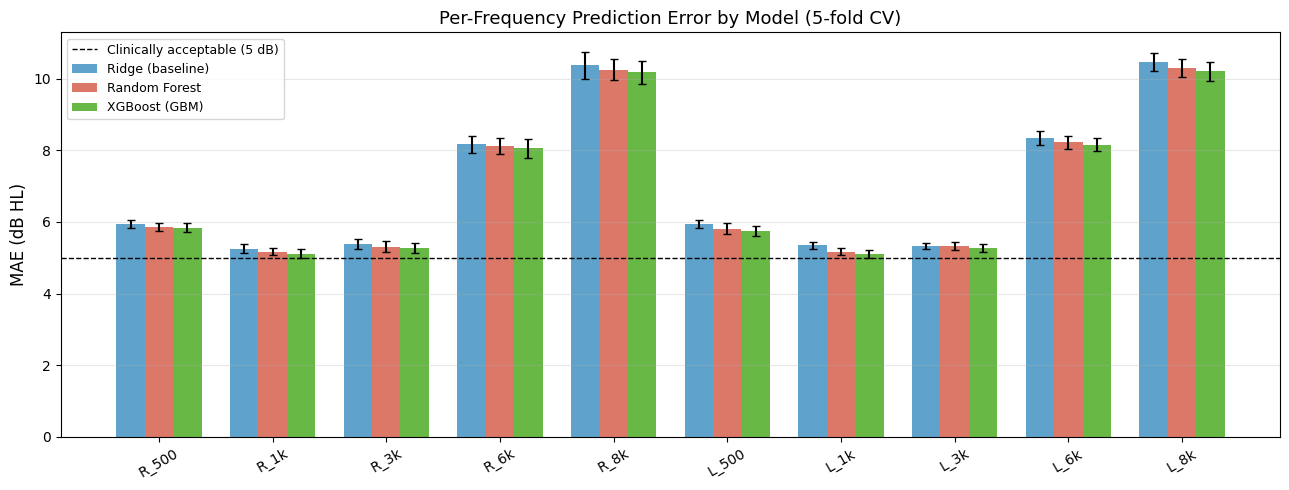

Saved: fig3_per_freq_mae.png


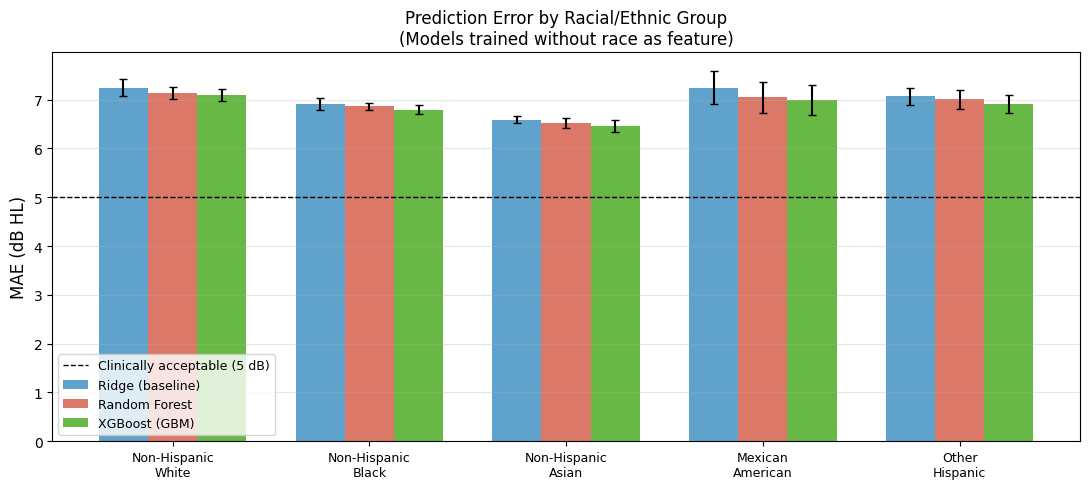

Saved: fig4_fairness_race_mae.png

=== STATISTICAL FAIRNESS TEST (Kruskal-Wallis) ===
H = 28.997, p = 0.0000
  Non-Hispanic White: median = 6.34 dB, IQR [4.81, 8.47]
  Non-Hispanic Black: median = 6.20 dB, IQR [4.82, 8.06]
  Non-Hispanic Asian: median = 5.83 dB, IQR [4.46, 7.75]
  Mexican American: median = 6.26 dB, IQR [4.73, 8.52]
  Other Hispanic: median = 6.10 dB, IQR [4.72, 8.22]

=== Pairwise Mann-Whitney U (Bonferroni corrected) ===

Group 1                   Group 2                     Med1   Med2      p-adj Sig
-------------------------------------------------------------------------------------
Non-Hispanic White        Non-Hispanic Black          6.34   6.20     0.5528 ns
Non-Hispanic White        Non-Hispanic Asian          6.34   5.83     0.0000 ***
Non-Hispanic White        Mexican American            6.34   6.26     1.0000 ns
Non-Hispanic White        Other Hispanic              6.34   6.10     0.9975 ns
Non-Hispanic Black        Non-Hispanic Asian          6.20   5.83  

In [3]:
# ============================================================
# CELL 3 — Modeling: Ridge / Random Forest / XGBoost
# 5-fold cross-validation + pairwise fairness tests
# Runtime: ~10-15 min on Colab CPU
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from scipy import stats
from itertools import combinations
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("/content/nhanes_all_cycles.csv")

FEATURES = ["age","gender","poverty_ratio",
            "R_2000Hz","R_4000Hz","L_2000Hz","L_4000Hz","any_noise_exposure"]
TARGETS  = ["R_500Hz","R_1000Hz","R_3000Hz","R_6000Hz","R_8000Hz",
            "L_500Hz","L_1000Hz","L_3000Hz","L_6000Hz","L_8000Hz"]
RACE_COL    = "race_eth_label"
RACE_ORDER  = ["Non-Hispanic White","Non-Hispanic Black","Non-Hispanic Asian",
               "Mexican American","Other Hispanic"]
RACE_COLORS = ["#2166ac","#d6604d","#4dac26","#f4a582","#762a83"]

keep   = list(dict.fromkeys(FEATURES + TARGETS + [RACE_COL,"HL_severity","cycle"]))
df_m   = df[[c for c in keep if c in df.columns]].copy()
df_m   = df_m.loc[:,~df_m.columns.duplicated()]
df_m   = df_m.dropna(subset=FEATURES+TARGETS)
print(f"Modeling N = {len(df_m)}")
print(df_m["cycle"].value_counts())

X      = df_m[FEATURES].values
y      = df_m[TARGETS].values
groups = df_m[RACE_COL].values

MODELS = {
    "Ridge (baseline)": MultiOutputRegressor(Ridge(alpha=1.0)),
    "Random Forest":    MultiOutputRegressor(
        RandomForestRegressor(n_estimators=200,max_depth=10,
                              min_samples_leaf=5,random_state=42,n_jobs=-1)),
    "XGBoost (GBM)":   MultiOutputRegressor(
        GradientBoostingRegressor(n_estimators=200,max_depth=4,
                                  learning_rate=0.05,subsample=0.8,random_state=42)),
}

kf      = KFold(n_splits=5,shuffle=True,random_state=42)
results = {}

for mname,model in MODELS.items():
    print(f"\nTraining: {mname}")
    fold_target_maes, fold_race_maes = [], {r:[] for r in RACE_ORDER}

    for fi,(tr,te) in enumerate(kf.split(X)):
        sc    = StandardScaler()
        Xtr   = sc.fit_transform(X[tr]); Xte = sc.transform(X[te])
        model.fit(Xtr,y[tr])
        pred  = model.predict(Xte)
        tmae  = [mean_absolute_error(y[te,:,None][:,j,0],pred[:,j]) for j in range(len(TARGETS))]
        fold_target_maes.append(tmae)
        for race in RACE_ORDER:
            mask = groups[te]==race
            if mask.sum()>=5:
                fold_race_maes[race].append(
                    mean_absolute_error(y[te][mask].ravel(),pred[mask].ravel()))
        print(f"  Fold {fi+1} overall MAE: {np.mean(tmae):.2f} dB")

    results[mname] = {
        "mean_target_mae": np.mean(fold_target_maes,axis=0),
        "std_target_mae":  np.std(fold_target_maes,axis=0),
        "mean_race_mae":   {r:np.mean(v) for r,v in fold_race_maes.items() if v},
        "std_race_mae":    {r:np.std(v)  for r,v in fold_race_maes.items() if v},
        "overall_mae":     np.mean(np.mean(fold_target_maes,axis=0)),
    }
    print(f"  Overall MAE: {results[mname]['overall_mae']:.2f} dB")

# ── Collect per-subject errors from best model ────────────────
best_name = min(results, key=lambda k: results[k]["overall_mae"])
print(f"\nBest model: {best_name}")

all_errors = np.zeros(len(df_m))
all_pred   = np.zeros_like(y)
best_model = MODELS[best_name]

for tr,te in kf.split(X):
    sc = StandardScaler()
    best_model.fit(sc.fit_transform(X[tr]),y[tr])
    pred = best_model.predict(sc.transform(X[te]))
    all_pred[te]   = pred
    all_errors[te] = np.abs(y[te]-pred).mean(axis=1)

df_m = df_m.copy()
df_m["subject_mae"] = all_errors
df_m.to_csv("/content/nhanes_model_results.csv",index=False)
print("Saved: nhanes_model_results.csv")

# ── Figure 3: Per-frequency MAE by model ─────────────────────
FREQ_LABELS = ["R_500","R_1k","R_3k","R_6k","R_8k","L_500","L_1k","L_3k","L_6k","L_8k"]
x = np.arange(len(TARGETS)); width=0.25
colors3 = ["#4393c3","#d6604d","#4dac26"]
fig,ax  = plt.subplots(figsize=(13,5))
for i,(mn,color) in enumerate(zip(MODELS.keys(),colors3)):
    ax.bar(x+i*width,results[mn]["mean_target_mae"],width,label=mn,color=color,
           alpha=0.85,yerr=results[mn]["std_target_mae"],capsize=3)
ax.set_xticks(x+width); ax.set_xticklabels(FREQ_LABELS,rotation=30,fontsize=10)
ax.set_ylabel("MAE (dB HL)",fontsize=12)
ax.set_title("Per-Frequency Prediction Error by Model (5-fold CV)",fontsize=13)
ax.axhline(5,color="black",linestyle="--",linewidth=1,label="Clinically acceptable (5 dB)")
ax.legend(fontsize=9); ax.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.savefig("fig3_per_freq_mae.png",dpi=300,bbox_inches="tight")
plt.show(); print("Saved: fig3_per_freq_mae.png")

# ── Figure 4: Fairness — overall MAE by race ─────────────────
x_race = np.arange(len(RACE_ORDER))
fig,ax = plt.subplots(figsize=(11,5))
for i,(mn,color) in enumerate(zip(MODELS.keys(),colors3)):
    vals = [results[mn]["mean_race_mae"].get(r,np.nan) for r in RACE_ORDER]
    errs = [results[mn]["std_race_mae"].get(r,np.nan)  for r in RACE_ORDER]
    ax.bar(x_race+i*width,vals,width,label=mn,color=color,alpha=0.85,yerr=errs,capsize=3)
ax.set_xticks(x_race+width); ax.set_xticklabels([r.replace(" ","\n") for r in RACE_ORDER],fontsize=9)
ax.set_ylabel("MAE (dB HL)",fontsize=12)
ax.set_title("Prediction Error by Racial/Ethnic Group\n(Models trained without race as feature)",fontsize=12)
ax.axhline(5,color="black",linestyle="--",linewidth=1,label="Clinically acceptable (5 dB)")
ax.legend(fontsize=9); ax.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.savefig("fig4_fairness_race_mae.png",dpi=300,bbox_inches="tight")
plt.show(); print("Saved: fig4_fairness_race_mae.png")

# ── Kruskal-Wallis ────────────────────────────────────────────
print("\n=== STATISTICAL FAIRNESS TEST (Kruskal-Wallis) ===")
race_errors = {r: df_m.loc[df_m[RACE_COL]==r,"subject_mae"].values for r in RACE_ORDER}
stat,p = stats.kruskal(*race_errors.values())
print(f"H = {stat:.3f}, p = {p:.4f}")
for r,e in race_errors.items():
    print(f"  {r}: median = {np.median(e):.2f} dB, IQR [{np.percentile(e,25):.2f}, {np.percentile(e,75):.2f}]")

# ── Pairwise Mann-Whitney + Bonferroni ────────────────────────
print("\n=== Pairwise Mann-Whitney U (Bonferroni corrected) ===")
pairs   = list(combinations(RACE_ORDER,2))
n_tests = len(pairs)
print(f"\n{'Group 1':<25} {'Group 2':<25} {'Med1':>6} {'Med2':>6} {'p-adj':>10} Sig")
print("-"*85)
for r1,r2 in pairs:
    e1,e2  = race_errors[r1], race_errors[r2]
    _,p    = stats.mannwhitneyu(e1,e2,alternative="two-sided")
    p_adj  = min(p*n_tests,1.0)
    sig    = "***" if p_adj<0.001 else ("**" if p_adj<0.01 else ("*" if p_adj<0.05 else "ns"))
    print(f"{r1:<25} {r2:<25} {np.median(e1):>6.2f} {np.median(e2):>6.2f} {p_adj:>10.4f} {sig}")

# ── Table 2: per-frequency performance ───────────────────────
print("\n=== TABLE 2: Per-Frequency Performance (XGBoost) ===")
freq_names = ["R 500Hz","R 1kHz","R 3kHz","R 6kHz","R 8kHz",
              "L 500Hz","L 1kHz","L 3kHz","L 6kHz","L 8kHz"]
print(f"\n{'Frequency':<12} {'MAE (dB)':>10} {'Within +/-5dB':>14} {'Within +/-10dB':>15}")
print("-"*53)
for j,fn in enumerate(freq_names):
    mae = mean_absolute_error(y[:,j],all_pred[:,j])
    w5  = np.mean(np.abs(y[:,j]-all_pred[:,j])<=5)*100
    w10 = np.mean(np.abs(y[:,j]-all_pred[:,j])<=10)*100
    print(f"{fn:<12} {mae:>10.2f} {w5:>13.1f}% {w10:>14.1f}%")
print(f"\nOverall MAE: {mean_absolute_error(y.ravel(),all_pred.ravel()):.2f} dB")


Computing SHAP (1,000-subsample, 10 targets)...
  1/10 done
  3/10 done
  5/10 done
  7/10 done
  9/10 done

SHAP importance (mean |SHAP|):
  L 4kHz              : 3.4471
  R 4kHz              : 3.1114
  R 2kHz              : 1.7234
  L 2kHz              : 1.6420
  Age                 : 1.6058
  Gender              : 0.3938
  Poverty Ratio       : 0.3148
  Noise Exp.          : 0.0315


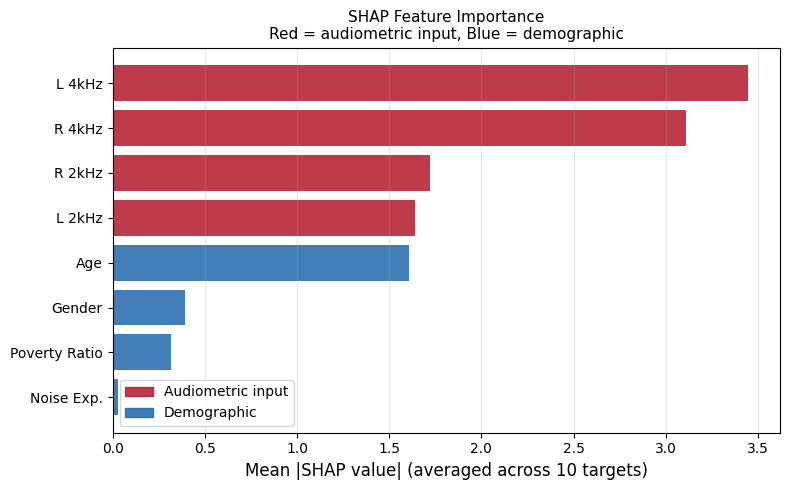

Saved: fig5_shap_importance.png

Running 5-fold CV for bootstrap analysis...

Race                      HL Cat                   n   Median             95% CI
--------------------------------------------------------------------------------
Non-Hispanic White        Normal (<25 dB)       2164     6.02       [5.89, 6.14]
Non-Hispanic White        Mild (25-40 dB)        258     9.04       [8.48, 9.47]
Non-Hispanic White        Mod+ (>=40 dB)          71     9.71      [8.91, 10.56]
Non-Hispanic Black        Normal (<25 dB)       1648     6.05       [5.90, 6.18]
Non-Hispanic Black        Mild (25-40 dB)        127     8.62       [7.62, 9.35]
Non-Hispanic Black        Mod+ (>=40 dB)          30    11.09      [9.17, 12.07]
Non-Hispanic Asian        Normal (<25 dB)        861     5.66       [5.46, 5.80]
Non-Hispanic Asian        Mild (25-40 dB)         73     8.71       [8.13, 9.66]
Non-Hispanic Asian        Mod+ (>=40 dB)          22     9.47      [7.77, 12.15]
Mexican American          Norma

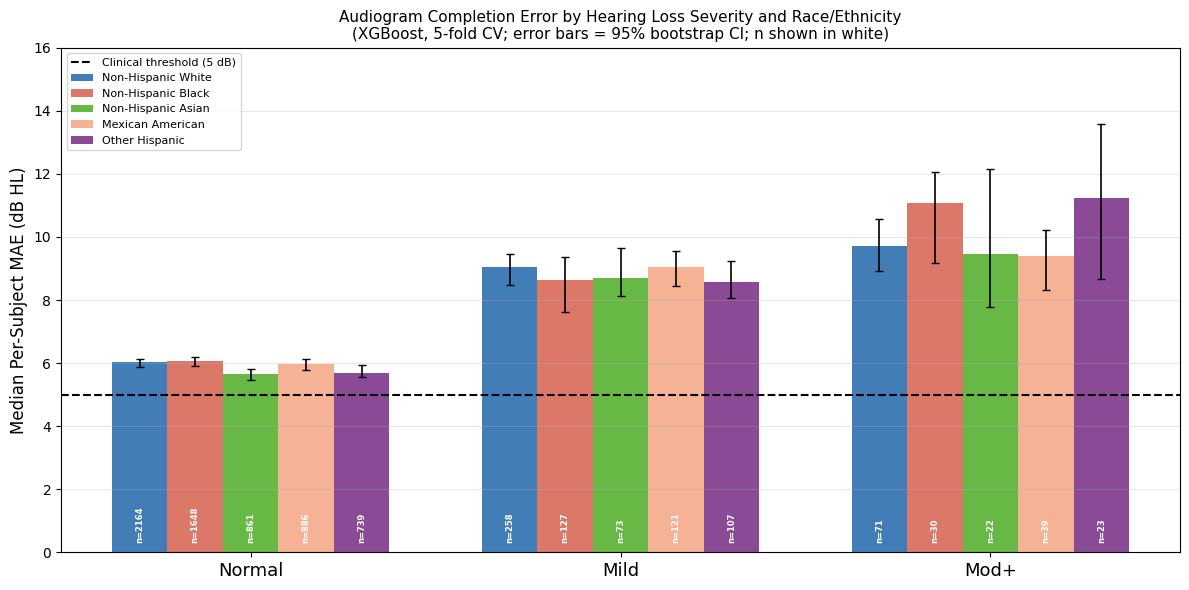

Saved: fig6_final_with_ci.png


In [4]:
# ============================================================
# CELL 4 — SHAP Feature Importance + Bootstrap CIs
# Figures 5 & 6
# Runtime: ~8-10 min on Colab CPU
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

try:
    import shap
except ImportError:
    import subprocess
    subprocess.run(["pip","install","shap","-q"])
    import shap

df_m = pd.read_csv("/content/nhanes_model_results.csv")
df   = pd.read_csv("/content/nhanes_all_cycles.csv")

FEATURES = ["age","gender","poverty_ratio",
            "R_2000Hz","R_4000Hz","L_2000Hz","L_4000Hz","any_noise_exposure"]
FEATURE_LABELS = ["Age","Gender","Poverty Ratio",
                  "R 2kHz","R 4kHz","L 2kHz","L 4kHz","Noise Exp."]
TARGETS = ["R_500Hz","R_1000Hz","R_3000Hz","R_6000Hz","R_8000Hz",
           "L_500Hz","L_1000Hz","L_3000Hz","L_6000Hz","L_8000Hz"]
RACE_COL   = "race_eth_label"
RACE_ORDER = ["Non-Hispanic White","Non-Hispanic Black","Non-Hispanic Asian",
              "Mexican American","Other Hispanic"]
# NOTE: ASCII labels — must match Cell 1 exactly
HL_CATS  = ["Normal (<25 dB)","Mild (25-40 dB)","Mod+ (>=40 dB)"]
HL_SHORT = ["Normal","Mild","Mod+"]

# ── Rebuild full X/y from raw data ────────────────────────────
keep = list(dict.fromkeys(FEATURES + TARGETS + [RACE_COL,"HL_severity"]))
df_full = df[[c for c in keep if c in df.columns]].copy()
df_full = df_full.loc[:,~df_full.columns.duplicated()]
df_full = df_full.dropna(subset=FEATURES+TARGETS)

X_full = df_full[FEATURES].values
y_full = df_full[TARGETS].values
sc_full = StandardScaler()
X_s    = sc_full.fit_transform(X_full)

# ── 1. SHAP ──────────────────────────────────────────────────
print("Computing SHAP (1,000-subsample, 10 targets)...")
np.random.seed(42)
idx   = np.random.choice(len(X_s), size=min(1000,len(X_s)), replace=False)
X_sh  = X_s[idx]
sv_all = np.zeros((len(X_sh), len(FEATURES)))

for j in range(len(TARGETS)):
    gb = GradientBoostingRegressor(n_estimators=100,max_depth=4,
                                   learning_rate=0.05,random_state=42)
    gb.fit(X_s, y_full[:,j])
    exp = shap.TreeExplainer(gb)
    sv_all += np.abs(exp.shap_values(X_sh))
    if j%2==0: print(f"  {j+1}/{len(TARGETS)} done")

shap_imp  = sv_all.mean(axis=0) / len(TARGETS)
sorted_p  = sorted(zip(FEATURE_LABELS,shap_imp), key=lambda x:x[1])
ft_sorted, im_sorted = zip(*sorted_p)

print("\nSHAP importance (mean |SHAP|):")
for f,v in sorted(zip(FEATURE_LABELS,shap_imp),key=lambda x:x[1],reverse=True):
    print(f"  {f:<20}: {v:.4f}")

fig,ax = plt.subplots(figsize=(8,5))
bar_colors = ["#b2182b" if "kHz" in f else "#2166ac" for f in ft_sorted]
ax.barh(ft_sorted, im_sorted, color=bar_colors, alpha=0.85)
ax.set_xlabel("Mean |SHAP value| (averaged across 10 targets)",fontsize=12)
ax.set_title("SHAP Feature Importance\nRed = audiometric input, Blue = demographic",fontsize=11)
ax.grid(axis="x",alpha=0.3)
ax.legend(handles=[
    mpatches.Patch(color="#b2182b",alpha=0.85,label="Audiometric input"),
    mpatches.Patch(color="#2166ac",alpha=0.85,label="Demographic"),
],fontsize=10)
plt.tight_layout()
plt.savefig("fig5_shap_importance.png",dpi=300,bbox_inches="tight")
plt.show(); print("Saved: fig5_shap_importance.png")

# ── 2. Bootstrap CIs for severity x race ─────────────────────
# Re-run 5-fold CV to get per-subject errors on full dataset
X_mod = df_full[FEATURES].values
y_mod = df_full[TARGETS].values
all_errors = np.zeros(len(df_full))

print("\nRunning 5-fold CV for bootstrap analysis...")
for tr,te in KFold(5,shuffle=True,random_state=42).split(X_mod):
    sc = StandardScaler()
    m  = MultiOutputRegressor(
        GradientBoostingRegressor(n_estimators=200,max_depth=4,
                                  learning_rate=0.05,subsample=0.8,random_state=42))
    m.fit(sc.fit_transform(X_mod[tr]), y_mod[tr])
    pred = m.predict(sc.transform(X_mod[te]))
    all_errors[te] = np.abs(y_mod[te]-pred).mean(axis=1)

df_full = df_full.copy()
df_full["subject_mae"] = all_errors

def boot_ci(arr, n=2000, ci=95):
    if len(arr)<5: return np.nan,np.nan,np.nan
    b = [np.median(np.random.choice(arr,size=len(arr),replace=True)) for _ in range(n)]
    return np.median(arr), np.percentile(b,(100-ci)/2), np.percentile(b,100-(100-ci)/2)

np.random.seed(42)
cell_data = {}
print(f"\n{'Race':<25} {'HL Cat':<20} {'n':>5} {'Median':>8} {'95% CI':>18}")
print("-"*80)
for race in RACE_ORDER:
    cell_data[race] = {}
    for hl in HL_CATS:
        mask = (df_full[RACE_COL]==race)&(df_full["HL_severity"]==hl)
        n    = mask.sum()
        errs = df_full.loc[mask,"subject_mae"].values
        med,lo,hi = boot_ci(errs)
        cell_data[race][hl] = {"n":n,"med":med,"lo":lo,"hi":hi}
        ci_str = f"[{lo:.2f}, {hi:.2f}]" if not np.isnan(med) else "N/A"
        print(f"{race:<25} {hl:<20} {n:>5} {med:>8.2f} {ci_str:>18}")

# ── Figure 6: Severity x Race with bootstrap CIs ─────────────
RACE_COLORS = ["#2166ac","#d6604d","#4dac26","#f4a582","#762a83"]
fig,ax = plt.subplots(figsize=(12,6))
x = np.arange(len(HL_CATS)); width=0.15

for i,(race,color) in enumerate(zip(RACE_ORDER,RACE_COLORS)):
    meds    = [cell_data[race][hl]["med"] for hl in HL_CATS]
    los     = [cell_data[race][hl]["lo"]  for hl in HL_CATS]
    his     = [cell_data[race][hl]["hi"]  for hl in HL_CATS]
    ns      = [cell_data[race][hl]["n"]   for hl in HL_CATS]
    yerr_lo = [m-l if not np.isnan(m) else 0 for m,l in zip(meds,los)]
    yerr_hi = [h-m if not np.isnan(m) else 0 for m,h in zip(meds,his)]
    bars = ax.bar(x+i*width,meds,width,label=race,color=color,alpha=0.85,
                  yerr=[yerr_lo,yerr_hi],capsize=3,error_kw={"linewidth":1.2})
    for j,(bar,n) in enumerate(zip(bars,ns)):
        if not np.isnan(meds[j]) and n>=5:
            ax.text(bar.get_x()+bar.get_width()/2, 0.3, f"n={n}",
                    ha="center",va="bottom",fontsize=6,rotation=90,
                    color="white",fontweight="bold")

ax.set_xticks(x+width*2); ax.set_xticklabels(HL_SHORT,fontsize=13)
ax.set_ylabel("Median Per-Subject MAE (dB HL)",fontsize=12)
ax.set_title("Audiogram Completion Error by Hearing Loss Severity and Race/Ethnicity\n"
             "(XGBoost, 5-fold CV; error bars = 95% bootstrap CI; n shown in white)",fontsize=11)
ax.axhline(5,color="black",linestyle="--",linewidth=1.5,label="Clinical threshold (5 dB)")
ax.legend(fontsize=8,loc="upper left")
ax.grid(axis="y",alpha=0.3); ax.set_ylim(0,16)
plt.tight_layout()
plt.savefig("fig6_final_with_ci.png",dpi=300,bbox_inches="tight")
plt.show(); print("Saved: fig6_final_with_ci.png")


Full modeling N = 7422
cycle
2015-2016    3878
2011-2012    3544
Name: count, dtype: int64

Train: 3544 | Test: 3878

Frequency      Temporal MAE  Within +/-5dB
------------------------------------------
R 500Hz                5.90          54.0%
R 1kHz                 5.26          58.6%
R 3kHz                 5.20          59.5%
R 6kHz                 8.02          41.4%
R 8kHz                10.17          33.1%
L 500Hz                5.86          53.7%
L 1kHz                 5.15          61.1%
L 3kHz                 5.26          58.6%
L 6kHz                 8.36          39.0%
L 8kHz                10.48          32.7%

Temporal overall MAE: 6.97 dB

=== CALIBRATION: Mean Signed Error by Race ===
(Positive = overestimate HL | Negative = underestimate HL)

Race                          n   Mean signed err       SD
----------------------------------------------------------
Non-Hispanic White         1214            -0.662    5.044  (underestimates HL)
Non-Hispanic Black          8

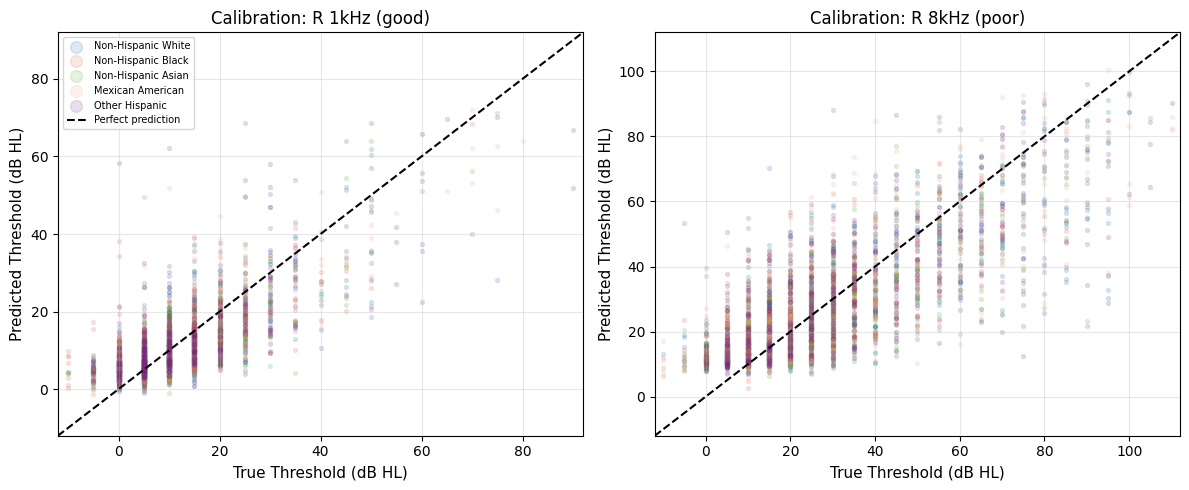

Saved: fig7_calibration.png

=== ALL EXPERIMENTS COMPLETE ===
Figures saved: fig1 through fig7
CSVs saved: nhanes_all_cycles.csv, nhanes_model_results.csv


In [5]:
# ============================================================
# CELL 5 — Temporal Validation + Calibration Analysis
# Figure 7
# Train: 2011-2012 + 2013-2014  |  Test: 2015-2016 + 2017-2018
# Runtime: ~5 min
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("/content/nhanes_all_cycles.csv")

FEATURES = ["age","gender","poverty_ratio",
            "R_2000Hz","R_4000Hz","L_2000Hz","L_4000Hz","any_noise_exposure"]
TARGETS  = ["R_500Hz","R_1000Hz","R_3000Hz","R_6000Hz","R_8000Hz",
            "L_500Hz","L_1000Hz","L_3000Hz","L_6000Hz","L_8000Hz"]
RACE_COL   = "race_eth_label"
RACE_ORDER = ["Non-Hispanic White","Non-Hispanic Black","Non-Hispanic Asian",
              "Mexican American","Other Hispanic"]
COLORS = {"Non-Hispanic White":"#2166ac","Non-Hispanic Black":"#d6604d",
          "Non-Hispanic Asian":"#4dac26","Mexican American":"#f4a582",
          "Other Hispanic":"#762a83"}

keep   = list(dict.fromkeys(FEATURES+TARGETS+[RACE_COL,"cycle"]))
df_m   = df[[c for c in keep if c in df.columns]].copy()
df_m   = df_m.loc[:,~df_m.columns.duplicated()]
df_m   = df_m.dropna(subset=FEATURES+TARGETS)
print(f"Full modeling N = {len(df_m)}")
print(df_m["cycle"].value_counts())

# ── Temporal split ────────────────────────────────────────────
train_mask = df_m["cycle"].isin(["2011-2012","2013-2014"])
test_mask  = df_m["cycle"].isin(["2015-2016","2017-2018"])
df_train   = df_m[train_mask]
df_test    = df_m[test_mask]
print(f"\nTrain: {len(df_train)} | Test: {len(df_test)}")

X_train = df_train[FEATURES].values; y_train = df_train[TARGETS].values
X_test  = df_test[FEATURES].values;  y_test  = df_test[TARGETS].values

sc = StandardScaler()
model_tv = MultiOutputRegressor(
    GradientBoostingRegressor(n_estimators=200,max_depth=4,
                              learning_rate=0.05,subsample=0.8,random_state=42))
model_tv.fit(sc.fit_transform(X_train), y_train)
y_pred_tv = model_tv.predict(sc.transform(X_test))

# ── Table: CV vs Temporal MAE ─────────────────────────────────
# CV MAEs computed fresh from Cell 3 model_results CSV
df_res = pd.read_csv("/content/nhanes_model_results.csv")
y_cv   = df_res[[c for c in TARGETS if c in df_res.columns]].values

freq_names = ["R 500Hz","R 1kHz","R 3kHz","R 6kHz","R 8kHz",
              "L 500Hz","L 1kHz","L 3kHz","L 6kHz","L 8kHz"]

print(f"\n{'Frequency':<12} {'Temporal MAE':>14} {'Within +/-5dB':>14}")
print("-"*42)
for j,fn in enumerate(freq_names):
    tv_mae = mean_absolute_error(y_test[:,j], y_pred_tv[:,j])
    w5     = np.mean(np.abs(y_test[:,j]-y_pred_tv[:,j])<=5)*100
    print(f"{fn:<12} {tv_mae:>14.2f} {w5:>13.1f}%")

print(f"\nTemporal overall MAE: {mean_absolute_error(y_test.ravel(),y_pred_tv.ravel()):.2f} dB")

# ── Calibration: signed error by race ────────────────────────
signed = y_pred_tv - y_test
df_te2 = df_test.reset_index(drop=True).copy()
df_te2["signed_mae"] = signed.mean(axis=1)

print(f"\n=== CALIBRATION: Mean Signed Error by Race ===")
print(f"(Positive = overestimate HL | Negative = underestimate HL)")
print(f"\n{'Race':<25} {'n':>5} {'Mean signed err':>17} {'SD':>8}")
print("-"*58)
for race in RACE_ORDER:
    mask = df_te2[RACE_COL]==race
    n    = mask.sum()
    m    = df_te2.loc[mask,"signed_mae"].mean()
    s    = df_te2.loc[mask,"signed_mae"].std()
    direction = "underestimates HL" if m<0 else "overestimates HL"
    print(f"{race:<25} {n:>5} {m:>17.3f} {s:>8.3f}  ({direction})")

# ── Figure 7: Calibration scatter plots ──────────────────────
fig,axes = plt.subplots(1,2,figsize=(12,5))
for ax,(j,fname) in zip(axes,[(1,"R 1kHz (good)"),(4,"R 8kHz (poor)")]):
    for race in RACE_ORDER:
        mask = df_te2[RACE_COL].values==race
        ax.scatter(y_test[mask,j],y_pred_tv[mask,j],
                   alpha=0.15,s=8,color=COLORS[race],label=race)
    lims = [min(y_test[:,j].min(),y_pred_tv[:,j].min())-2,
            max(y_test[:,j].max(),y_pred_tv[:,j].max())+2]
    ax.plot(lims,lims,"k--",linewidth=1.5,label="Perfect prediction")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("True Threshold (dB HL)",fontsize=11)
    ax.set_ylabel("Predicted Threshold (dB HL)",fontsize=11)
    ax.set_title(f"Calibration: {fname}",fontsize=12)
    if j==1: ax.legend(fontsize=7,markerscale=3)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig7_calibration.png",dpi=300,bbox_inches="tight")
plt.show(); print("Saved: fig7_calibration.png")

print("\n=== ALL EXPERIMENTS COMPLETE ===")
print("Figures saved: fig1 through fig7")
print("CSVs saved: nhanes_all_cycles.csv, nhanes_model_results.csv")
